# Inside one market: why a two-sided pair maker loses

Each Polymarket BTC 5-minute market pays $1 to exactly one side, UP or DOWN. A pair maker rests small buy orders on
both sides and hopes to own one share of each for under $1 in total. The [full study](../reports/pair_maker_btc_5m.md)
shows that over 7,699 markets it loses about 2% of the money it spends.

This notebook replays the strategy on **one real recorded market** from the bundled sample (`data/sample/`, no download
needed) and shows *where* the money goes. Run it from the `notebooks/` folder after `pip install -e ".[research]"`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pmlab.backtest.resting_engine import EngineConfig, load_events, run_market
from pmlab.backtest.runner import market_files
from pmlab.data.loaders import ASK, BID, load_books
from pmlab.data.outcomes import load_outcomes, winner_of
from pmlab.strategies.pair_maker import PairMaker

SAMPLE = Path("..") / "data" / "sample"
FILES = market_files(SAMPLE, "btc_5m_data")
OUTCOMES = load_outcomes(SAMPLE / "outcomes.json")

# The version chosen in the study, and the same fill model (orders join the back of the queue, 0.25 s decisions)
PARAMS = dict(pair_max=0.94, shares=10, max_ratio=1.3, budget=300)
CONFIG = EngineConfig(dt=0.25, cross=True, queue="last", duration=300)
UP_COLOR, DOWN_COLOR, MUTED = "#2a78d6", "#eb6834", "#52514e"
sorted(FILES)

[1794027900, 1794038100, 1794041100, 1794072000]

## 1. The order book, second by second

`load_books` turns the recording into an *as-of* array: row `t` holds the best bid and ask each side had at second `t`,
using only messages received up to then, so nothing from the future leaks into a decision.

In [2]:
START = 1794038100  # Nov 7, 2:55-3:00 AM ET
_, books = load_books(FILES[START], duration_seconds=300)
mid = (books[:, :, BID] + books[:, :, ASK]) / 2  # shape (300 seconds, 2 sides)
print("books:", books.shape, "  UP mid every minute:", np.round(mid[::60, 0], 2))

books: (300, 2, 5)   UP mid every minute: [0.48 0.56 0.36 0.12 0.55]


UP opens near 50c, climbs to about 75c, collapses to about 10c in the third minute, then rallies in the last
minute and wins. A market that swings both ways should be the friendliest case for a pair maker: each side is cheap at
some point.

## 2. Replay the pair maker

`load_events` reads every book change and trade print in time order; `run_market` steps the strategy every 0.25 s,
places its bids with a 0.13 s delay, keeps track of how many shares are ahead of it in the queue, and fills it only when
traders actually sell into its price (or the ask comes down to it).

In [3]:
condition_id, events = load_events(FILES[START], START)
winner = winner_of(OUTCOMES[condition_id])
result = run_market(events, winner, PairMaker(**PARAMS), CONFIG)
fills = pd.DataFrame(result["log"], columns=["t", "side", "price", "shares", "why"])

avg = {}
for side, name in ((0, "up"), (1, "down")):
    avg[side] = result[f"cost_{name}"] / result[name]
    print(f"{name.upper():5} {result[name]:6.1f} shares for ${result[f'cost_{name}']:6.2f}  (average {avg[side]:.3f})")
print(f"pair cost: ${avg[0] + avg[1]:.3f} for a $1 payout")
print(f"profit: ${result['gross']:.2f} on ${result['cost']:.2f} spent, {len(fills)} fills")

UP     286.6 shares for $131.37  (average 0.458)
DOWN   306.1 shares for $184.08  (average 0.601)
pair cost: $1.060 for a $1 payout
profit: $-28.84 on $315.45 spent, 80 fills


The bot ends nearly balanced (about 290 shares a side), yet each pair cost $1.06 for a $1 payout. The chart
shows how.

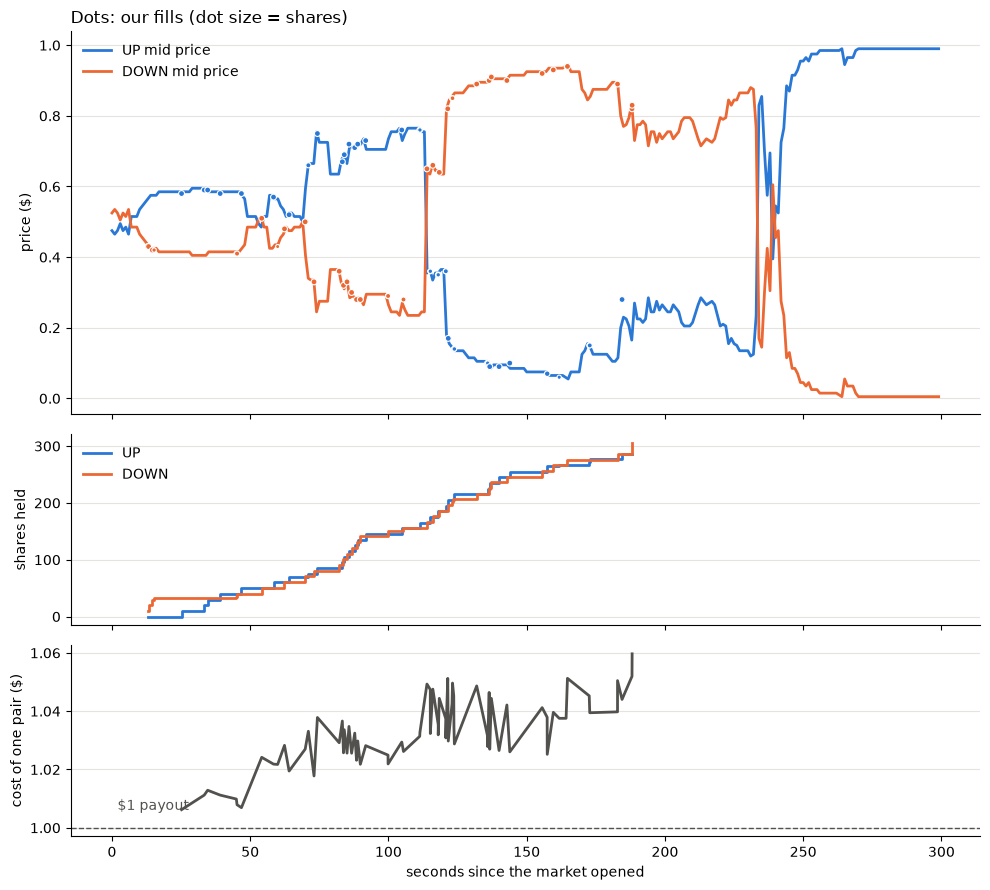

In [4]:
fills = fills.sort_values("t")
held = fills.pivot_table(index="t", columns="side", values="shares", aggfunc="sum").fillna(0).cumsum()
spent = (
    fills.assign(dollars=fills.price * fills.shares)
    .pivot_table(index="t", columns="side", values="dollars", aggfunc="sum")
    .fillna(0)
    .cumsum()
)
pair_cost = (spent[0] / held[0] + spent[1] / held[1]).where((held[0] > 0) & (held[1] > 0))

fig, (a, b, c) = plt.subplots(3, 1, figsize=(10, 9), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
for side, color, name in ((0, UP_COLOR, "UP"), (1, DOWN_COLOR, "DOWN")):
    a.plot(np.arange(300), mid[:, side], color=color, linewidth=2, label=f"{name} mid price")
    f = fills[fills.side == side]
    a.scatter(f.t, f.price, s=8 + f.shares, color=color, edgecolor="white", linewidth=0.8, zorder=3)
    b.step(held.index, held[side], where="post", color=color, linewidth=2, label=name)
a.set_ylabel("price ($)")
a.set_title("Dots: our fills (dot size = shares)", loc="left")
a.legend(frameon=False, loc="upper left")
b.set_ylabel("shares held")
b.legend(frameon=False, loc="upper left")
c.plot(pair_cost.index, pair_cost, color=MUTED, linewidth=2)
c.axhline(1.0, color=MUTED, linewidth=1, linestyle="--")
c.text(2, 1.005, "$1 payout", color=MUTED, va="bottom")
c.set_ylabel("cost of one pair ($)")
c.set_xlabel("seconds since the market opened")
for ax in (a, b, c):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e4e3df")
fig.tight_layout()

**What the chart shows.**

* **No margin to start with.** When the spread is 2c or wider the bot bids 1c above the best bid, which is about the
  middle of the spread. The two sides' middles add up to $1, so the first pair (DOWN at 42-43c, then UP at 58-59c)
  already costs about $1.01.
* **It only gets worse.** The rule "never pay more than 94c a pair" stops the bot from adding to the *heavier* side,
  but the lighter side may always be bought to complete pairs, at whatever it costs by then. After every jump the bot
  completes pairs at the new, worse price, so the pair cost climbs from $1.01 to $1.06.
* The bot stops buying at about 190 s because it has spent its $300 budget.

## 3. Are we filled just before the price moves against us?

If fills were random, the price of the side we just bought would on average stay where we bought it. Below, for every
fill in the four sample markets, we compare the fill price with that side's mid price 5 and 30 seconds later
(averaged over shares: negative means the price fell after we bought).

In [5]:
moves = []
for start, path in sorted(FILES.items()):
    cid, ev = load_events(path, start)
    log = run_market(ev, winner_of(OUTCOMES[cid]), PairMaker(**PARAMS), CONFIG)["log"]
    _, b = load_books(path, duration_seconds=300)
    m = (b[:, :, BID] + b[:, :, ASK]) / 2
    for t, side, price, shares, why in log:
        later = {h: m[min(max(int(np.ceil(t)), 0) + h, 299), side] - price for h in (5, 30)}
        moves.append(dict(start=start, how_filled=why, shares=shares, after_5s=later[5], after_30s=later[30]))
moves = pd.DataFrame(moves)


def per_share(g):
    return pd.Series(
        {
            "fills": len(g),
            "shares": g.shares.sum(),
            "after 5 s (c)": 100 * np.average(g.after_5s, weights=g.shares),
            "after 30 s (c)": 100 * np.average(g.after_30s, weights=g.shares),
        }
    )


pd.concat([moves.groupby("how_filled").apply(per_share), per_share(moves).to_frame("all fills").T]).round(2)

,fills,shares,after 5 s (c),after 30 s (c)
cross,66.0,583.74,-3.00,-3.31
queue,107.0,727.28,-0.56,-1.77
through,14.0,138.00,-0.64,2.25
all fills,187.0,1449.02,-1.55,-2.01


On average the side we just bought is about 1.6c cheaper 5 seconds later and 2c cheaper 30 seconds later. The
worst fills are the `cross` ones, where the ask came down to our bid: the sellers were in a hurry, and they were right.
This is **adverse selection**: a resting bid is filled most readily exactly when the price is about to move against it.
Four markets are far too few to prove anything on their own; the full study measures the resulting loss across 7,699
markets.

## 4. The four sample markets

In [6]:
rows = []
for start, path in sorted(FILES.items()):
    cid, ev = load_events(path, start)
    r = run_market(ev, winner_of(OUTCOMES[cid]), PairMaker(**PARAMS), CONFIG)
    rows.append(
        dict(
            start=pd.Timestamp(start, unit="s", tz="America/New_York").strftime("%b %d %H:%M"),
            winner="UP" if r["win"] == 0 else "DOWN",
            up_shares=round(r["up"]),
            down_shares=round(r["down"]),
            pair_cost=round(r["cost_up"] / r["up"] + r["cost_down"] / r["down"], 3),
            spent=round(r["cost"], 2),
            profit=round(r["gross"], 2),
        )
    )
table = pd.DataFrame(rows)
table

,start,winner,up_shares,down_shares,pair_cost,spent,profit
0,Nov 07 00:05,DOWN,90,90,1.023,92.10,-2.10
1,Nov 07 02:55,UP,287,306,1.060,315.45,-28.84
2,Nov 07 03:45,UP,223,214,1.025,226.81,-4.09
3,Nov 07 12:20,UP,120,120,0.988,118.60,1.40


Every market ends balanced, so the result depends almost entirely on the price paid for a pair. Only the 12:20
market, a steady one-way move, came in under $1. These four rows are identical to the same markets in
`reports/pair_maker_btc_5m_exam_markets.csv` (a test checks it).

**Next:** the [full study](../reports/pair_maker_btc_5m.md) runs 12 versions over 7,699 markets with a time-ordered
train / validation / exam split and an independent second simulator.